In [19]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

(4611, 2570)


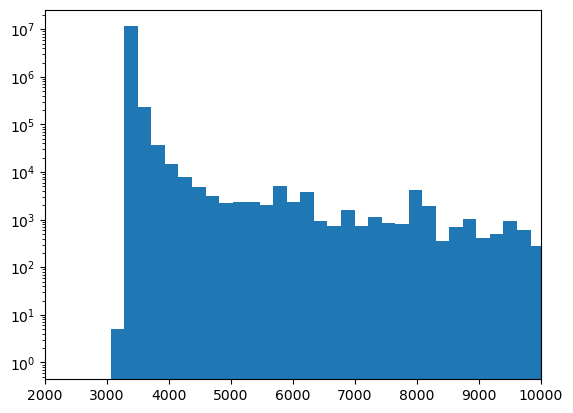

In [ ]:
pixel_values = fits.getdata("mosaic.fits")
image = pixel_values.astype(float)

print(image.shape)

x = []

for i in range(len(image)):
    for j in range(len(image[0])):
        pixel_value = image[i,j]
        x.append(pixel_value)

#print(x)

plt.hist(x, bins = 300) #,histtype = "step")
plt.yscale("log")
plt.xlim(2000,10000)
#plt.ylim(0,1000)
plt.show()


In [ ]:
counts, edges = np.histogram(x,bins=300)
index_maxpeak = np.argmax(counts)
left_edge = edges[index_maxpeak]
right_edge = edges[index_maxpeak+1]
print(left_edge, right_edge)


3276.75 3495.2


3418.748120384511 12.336586426444255


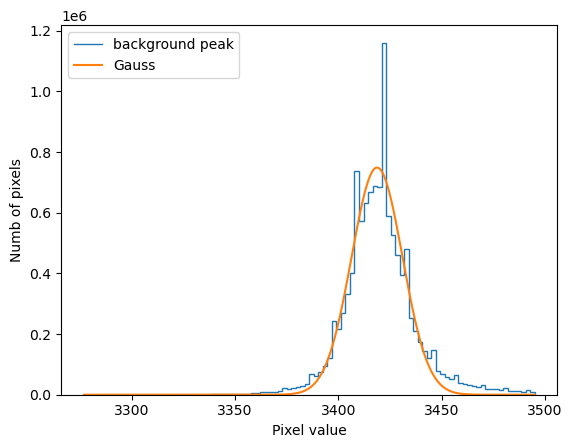

In [ ]:
counts, edges = np.histogram(x, bins=100, range=(left_edge, right_edge))

centres = (edges[:-1] + edges[1:]) / 2
def gaussian(v, amplitude, mean, sigma):
    return amplitude * np.exp(-0.5 * ((v - mean) / sigma)**2)

guess = [counts.max(), centres[np.argmax(counts)], 15]

parameters, covariance = curve_fit(gaussian,centres,counts,p0=guess,
            bounds=([0, left_edge, 0.1],[np.inf, right_edge, right_edge - left_edge]))

amplitude, mean, sigma = parameters

v = np.linspace(left_edge, right_edge, 1000)
plt.figure()
plt.stairs(counts, edges, label="background peak")
plt.plot(v, gaussian(v, *parameters), label="Gauss")
plt.xlabel("Pixel value")
plt.ylabel("Numb of pixels")
plt.legend()
plt.show()

In [ ]:
background = mean
noise = sigma 
print(mean, sigma)
detection_thres = background + 5 * sigma


3418.748120384511 12.336586426444255


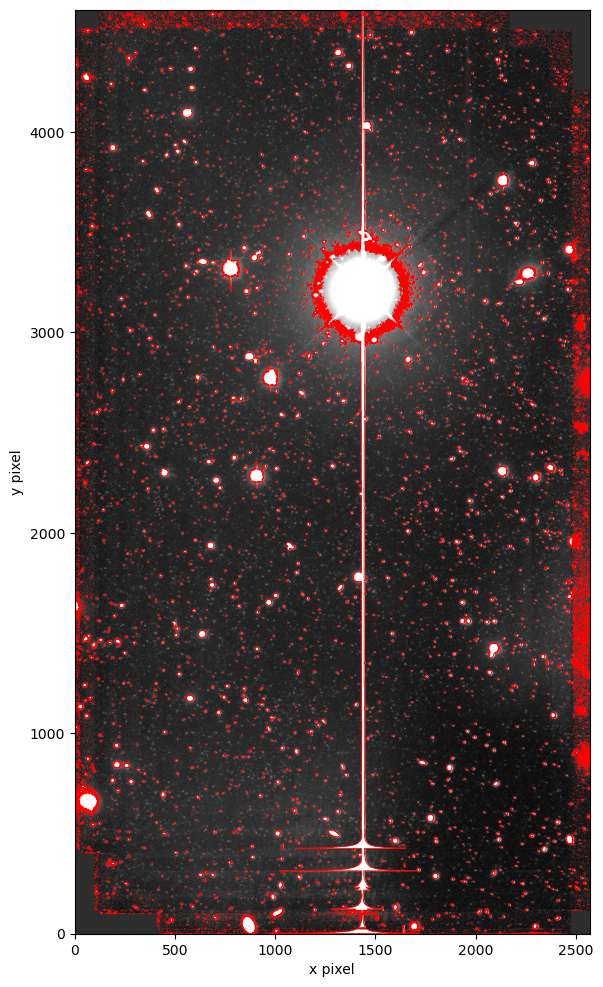

In [29]:
detected_pixels = image > detection_thres

fig, ax = plt.subplots(figsize=(10, 12))

ax.imshow(image,origin="lower",cmap="gray",vmin=mean - 2 * sigma,vmax=mean + 10 * sigma)
ax.contour(detected_pixels.astype(float),levels=[0.5],colors="red",linewidths=0.6)

ax.set_xlabel("x pixel")
ax.set_ylabel("y pixel")
plt.show()